> https://www.kaggle.com/code/cosmosankur/decision-tree

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, dirnames, filenames in os.walk('./'):
    print(dirname)
    print(dirnames)
    print(filenames)
    for filename in filenames:
        print(os.path.join(dirname, filename))

./
['assets', 'Input']
['decision_tree.py', 'dt.ipynb', 'dt.py', 'kaggle.ipynb', 'README.md', 'unit_test.py']
./decision_tree.py
./dt.ipynb
./dt.py
./kaggle.ipynb
./README.md
./unit_test.py
./assets
[]
['dtree.png', 'dtree2.png', 'dtreep.png', 'Economics_Gini_coefficient2.svg', '熵与概率的关系.png']
./assets\dtree.png
./assets\dtree2.png
./assets\dtreep.png
./assets\Economics_Gini_coefficient2.svg
./assets\熵与概率的关系.png
./Input
[]
['data_5-1.txt', 'data_5-2.txt', 'mdata_5-1.txt', 'movie_success_rate.csv']
./Input\data_5-1.txt
./Input\data_5-2.txt
./Input\mdata_5-1.txt
./Input\movie_success_rate.csv


In [2]:
df = pd.read_csv('./input/movie_success_rate.csv')
print(df.shape)

(839, 33)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                838 non-null    float64
 1   Title               838 non-null    str    
 2   Genre               838 non-null    str    
 3   Description         838 non-null    str    
 4   Director            838 non-null    str    
 5   Actors              838 non-null    str    
 6   Year                838 non-null    float64
 7   Runtime (Minutes)   838 non-null    float64
 8   Rating              839 non-null    float64
 9   Votes               839 non-null    float64
 10  Revenue (Millions)  839 non-null    float64
 11  Metascore           838 non-null    float64
 12  Action              838 non-null    float64
 13  Adventure           838 non-null    float64
 14  Aniimation          838 non-null    float64
 15  Biography           838 non-null    float64
 16  Comedy             

In [4]:
print(df['Genre'].value_counts())

Genre
Action,Adventure,Sci-Fi       50
Comedy,Drama,Romance          30
Drama                         29
Drama,Romance                 27
Animation,Adventure,Comedy    26
                              ..
Drama,Fantasy,Musical          1
Adventure,Family               1
Adventure,Comedy,Fantasy       1
Drama,Family,Music             1
Comedy,Family,Fantasy          1
Name: count, Length: 189, dtype: int64


In [5]:
print(df['Director'].value_counts())

Director
Ridley Scott          8
David Yates           6
Paul W.S. Anderson    6
Michael Bay           6
M. Night Shyamalan    5
                     ..
Steven Quale          1
Shana Feste           1
Patrick Tatopoulos    1
Aamir Khan            1
Nima Nourizadeh       1
Name: count, Length: 524, dtype: int64


In [6]:
df['Actors'].value_counts()

Actors
Daniel Radcliffe, Emma Watson, Rupert Grint, Michael Gambon            2
Shia LaBeouf, Megan Fox, Josh Duhamel, Tyrese Gibson                   2
Jennifer Lawrence, Josh Hutcherson, Liam Hemsworth, Woody Harrelson    2
Gerard Butler, Aaron Eckhart, Morgan Freeman,Angela Bassett            2
Chris Pratt, Vin Diesel, Bradley Cooper, Zoe Saldana                   1
                                                                      ..
Milla Jovovich, Ali Larter, Wentworth Miller,Kim Coates                1
Thomas Mann, Oliver Cooper, Jonathan Daniel Brown, Dax Flame           1
Lauren German, Heather Matarazzo, Bijou Phillips, Roger Bart           1
Robert Hoffman, Briana Evigan, Cassie Ventura, Adam G. Sevani          1
Kevin Spacey, Jennifer Garner, Robbie Amell,Cheryl Hines               1
Name: count, Length: 834, dtype: int64

<Axes: >

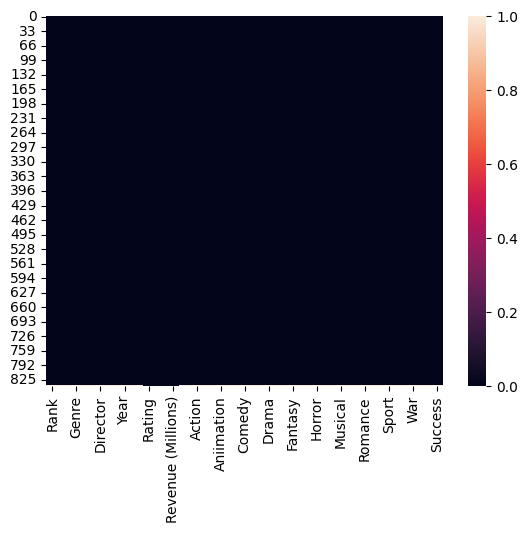

In [7]:
import seaborn as sns
sns.heatmap(df.isnull())
# 整张图几乎全是深色（接近黑色）说明你的数据集中 几乎没有缺失值！也就是说，对于所有 826 行 × 17 列的数据，绝大多数单元格都有有效数据，没有 NaN。

In [8]:
def handle_missing_value(df):
    # 缺失值填充
    from  sklearn.impute import SimpleImputer
    # 分离数值型和非数值型列
    numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_features = df.select_dtypes(include=['object']).columns.tolist()

    # 创建不同的 imputer
    # 中位数
    numeric_inputer = SimpleImputer(strategy='median')
    # 众数
    categoryical_imputer = SimpleImputer(strategy='most_frequent')

    const_imputer = SimpleImputer(strategy='constant',fill_value='Missing')

    # 应用
    if numeric_features:
        df[numeric_features] = numeric_inputer.fit_transform(df[numeric_features])
    if categorical_features:
        df[categorical_features] = categoryical_imputer.fit_transform(df[categorical_features])

In [14]:
df = df.fillna(df.min())
x = df[['Year',
       'Runtime (Minutes)', 'Rating', 'Votes', 'Revenue (Millions)',
       'Metascore', 'Action', 'Adventure', 'Aniimation', 'Biography', 'Comedy',
       'Crime', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music',
       'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Sport', 'Thriller', 'War',
       'Western']]
y = df['Success']
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.1)

In [15]:
from sklearn.linear_model import LinearRegression
net = LinearRegression(fit_intercept=True)
net.fit(x_train,y_train)
print(net)

LinearRegression()


In [16]:
print(net.score(x_train,y_train))
print(net.score(x_test,y_test))

0.529959401305383
0.6244875399177279


In [20]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(x_train,y_train)
accuracy_score(y_test,knn.predict(x_test))

0.9404761904761905

In [ ]:
from sklearn.tree import DecisionTreeClassifier
# 在 scikit-learn 的代码实现中，"entropy" 和 "log_loss" 指向的是完全相同的数学计算逻辑
# 引入 "log_loss" 这个选项主要是为了语义一致性和API 统一：
dt = DecisionTreeClassifier(criterion='log_loss')
dt.fit(x_train,y_train)
print(accuracy_score(y_test,dt.predict(x_test)))
print(dt.score(x_test,y_test))

1.0
1.0


<Axes: >

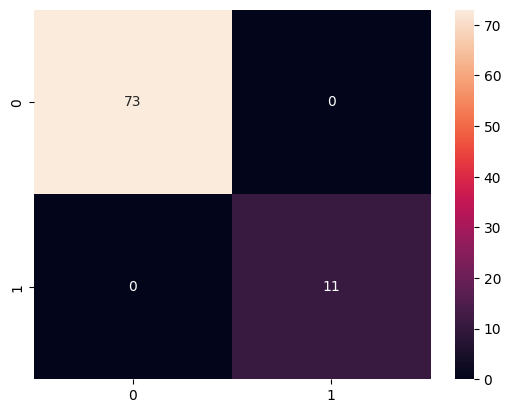

In [26]:
from sklearn.metrics import confusion_matrix
cfm = confusion_matrix(y_test,dt.predict(x_test))
sns.heatmap(cfm,annot=True)